In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import json
import pandas as pd
import torch
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from torch import nn 
import torch.nn.functional as F
from torchvision.transforms import v2
import random
import numpy as np
import math
import time

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()

seed_everything()

## 1. Data

In [3]:
class LeafDataset():
    def __init__(self, df, images, transform, has_labels=True):
        images_dir = Path(images)
        self.paths = [images_dir / name for name in df["image_id"]]
        self.labels = (
            df["label"].to_numpy(dtype="int64", copy=True)
            if "label" in df.columns
            else None
        )    
        self.transform = transform

    def __len__(self):
        return len(self.paths)
        
    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = image.convert("RGB")
            if self.transform is not None:
                image = self.transform(image)

        return image, int(self.labels[index])

In [4]:
ROOT = Path("/kaggle/input/competitions/cassava-leaf-disease-classification")
with open(ROOT / "label_num_to_disease_map.json", encoding="utf-8") as file:
    label_names = json.load(file)

df = pd.read_csv(ROOT / "train.csv")
train_df, val_test_df = train_test_split(
    df, 
    test_size=0.2,
    stratify=df["label"],
    random_state=SEED
)
val_df, test_df = train_test_split(
    val_test_df, 
    test_size=0.5,
    stratify=val_test_df["label"],
    random_state=SEED
)

In [5]:
IMAGE_SIZE = 224

transform = v2.Compose([
    v2.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

train_dataset = LeafDataset(train_df, ROOT / "train_images", transform)
val_dataset = LeafDataset(val_df, ROOT / "train_images", transform)
test_dataset = LeafDataset(test_df, ROOT / "train_images", transform)

In [6]:
def show_samples(dataset, label_names, n=6, cols=2):
    indices = random.sample(range(len(dataset)), n)
    rows = (n + cols - 1) // cols

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(cols * 4, rows * 4),
        squeeze=False,
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, index in zip(axes.flat, indices):
        image, label = dataset[index]
        if isinstance(image, torch.Tensor):
            image = image.detach().cpu().permute(1, 2, 0)

        ax.imshow(image)
        ax.set_title(
            label_names[str(label)],
            fontsize=9,
        )

    plt.tight_layout()
    plt.show()

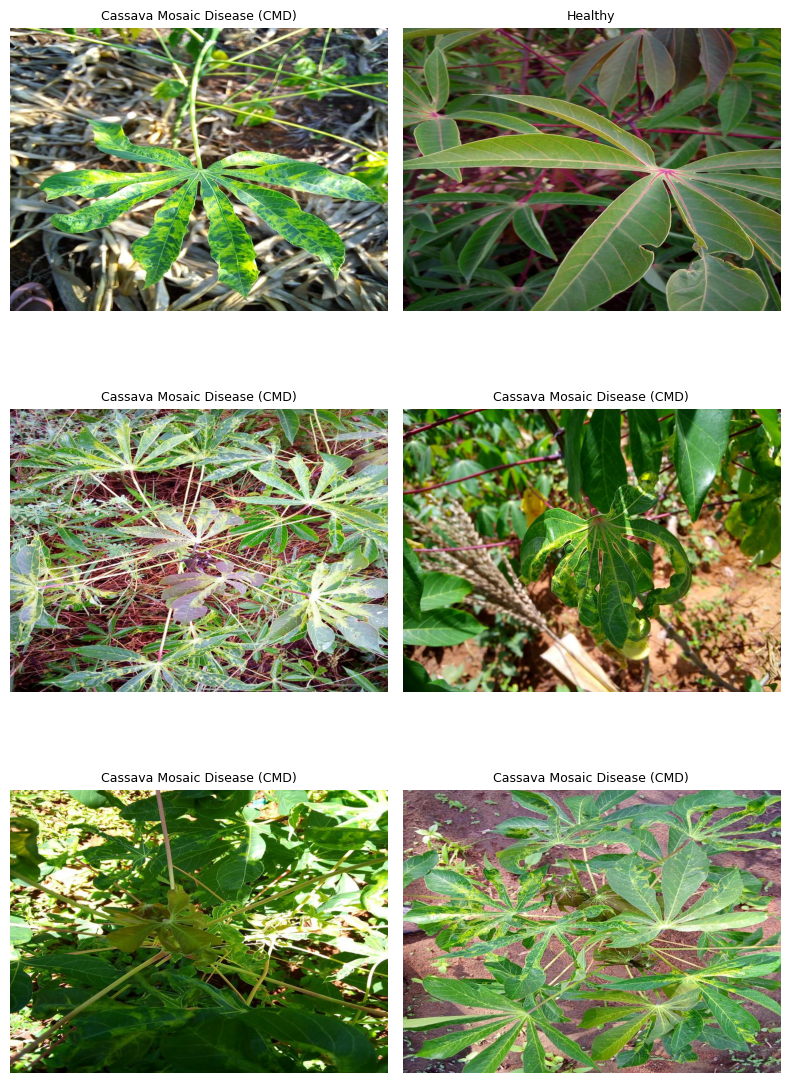

In [7]:
vis_dataset = LeafDataset(train_df, ROOT / "train_images", None)
show_samples(vis_dataset, label_names, n=6, cols=2)

In [8]:
BATCH_SIZE = 32
NUM_WORKERS = 2
use_cuda = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=use_cuda
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=use_cuda
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=use_cuda
)

# 2. Models

## 2.1 ViT

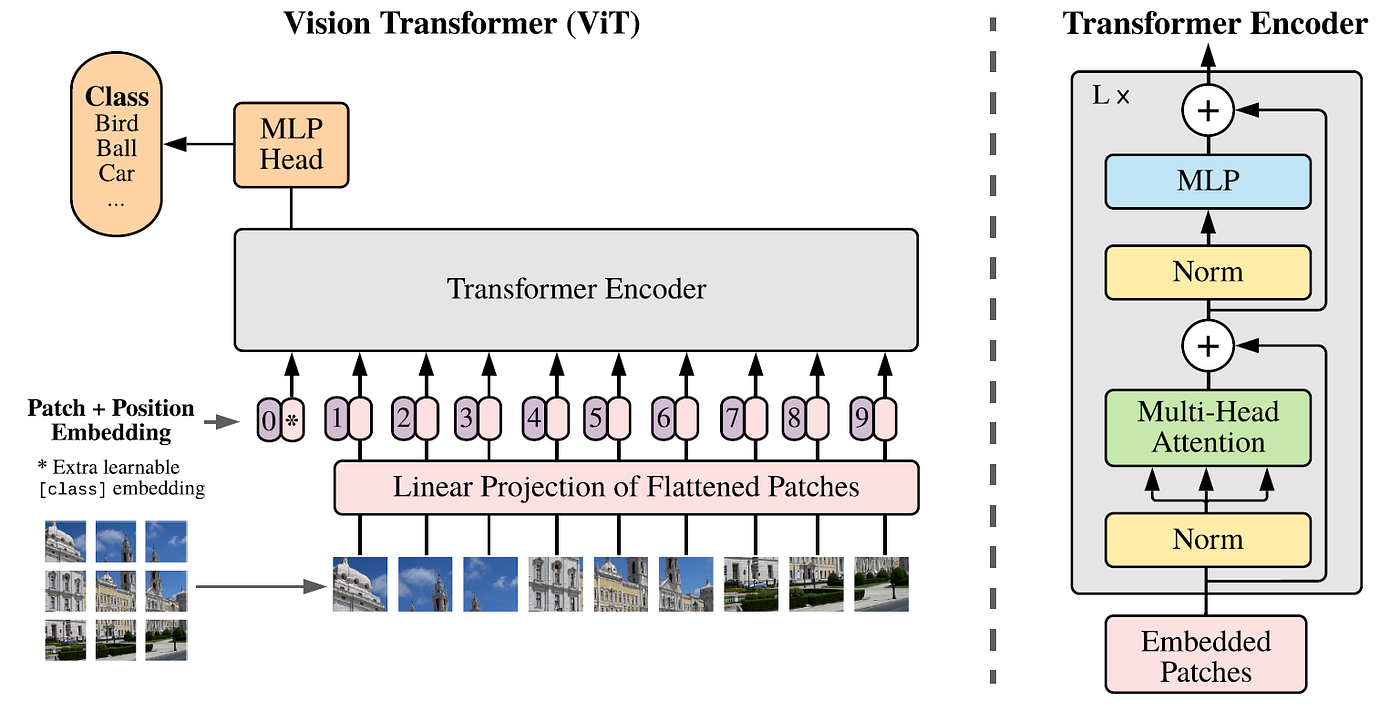
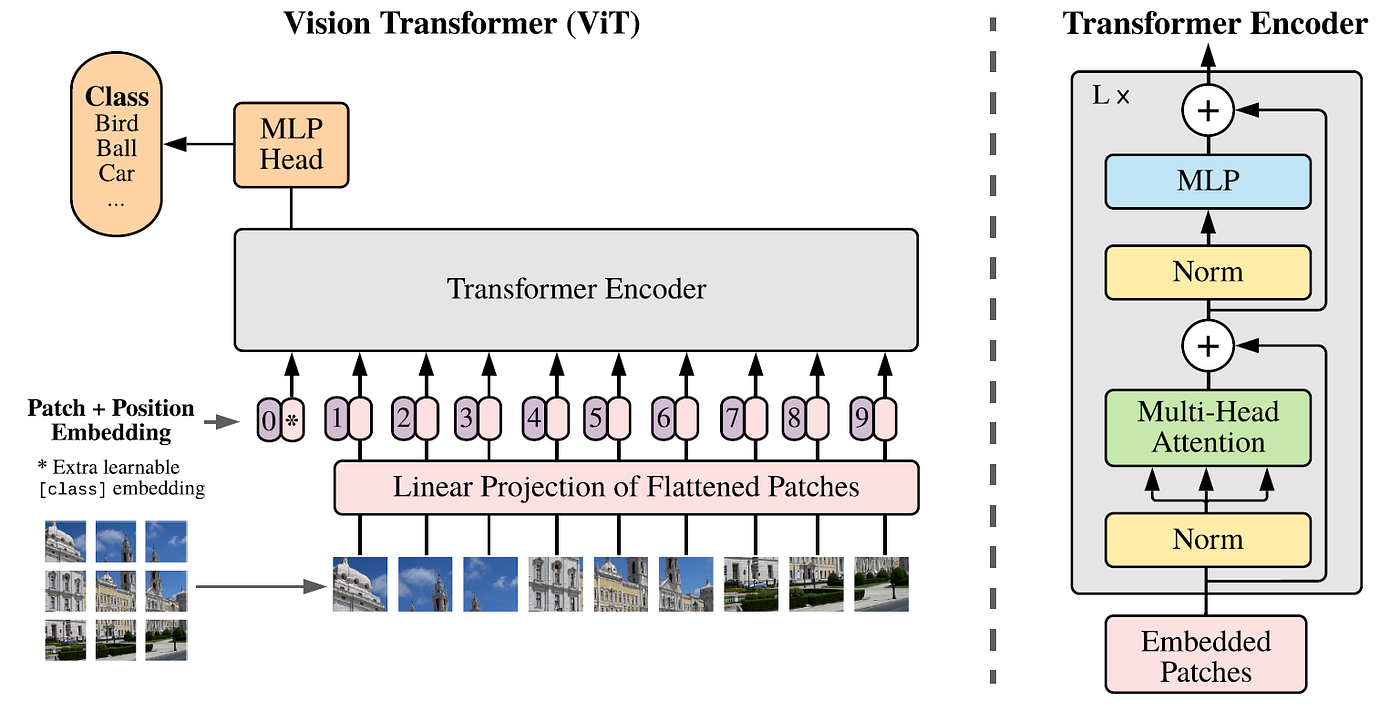

### 2.1.1 Patches Embedings
Getting embedings from images

In [9]:
class PatchEmbedding(nn.Module):
    def __init__(self, image_size, patch_size, in_channels, embed_dim):
        super().__init__()
        assert image_size % patch_size == 0
        self.image_size = image_size
        self.patch_size = patch_size
        self.num_patches = (image_size // patch_size) ** 2
        self.proj = nn.Conv2d(
            in_channels,
            embed_dim,
            patch_size,
            patch_size
        )

    def forward(self, images):
        """
        images: (B, 3, H, W)
        emb: (B, N, D)
        """
        emb = self.proj(images).flatten(2).transpose(1, 2)
        return emb

### 2.1.2 Multi-Head self-attention
Counting image self-attention in *n* heads, then concatenating results from them and sending through Linear layer

In [10]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout=0.0):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        self.qkv = nn.Linear(embed_dim, 3 * embed_dim)
        self.attn_dropout = nn.Dropout(dropout)

        self.out_proj = nn.Linear(embed_dim, embed_dim)
        self.proj_dropout = nn.Dropout(dropout)

    def forward(self, x):
        """
        x: (B, T, D)
        output, attn_w: (B, T, D), (B, num_heads, T, T)
        """
        B, T, D = x.shape
        qkv = self.qkv(x).reshape(B, T, self.num_heads, self.head_dim, 3).transpose(1, 2)
        q, k, v = qkv.unbind(dim=-1)

        attn_w = torch.softmax(q @ k.transpose(-1, -2) / math.sqrt(self.head_dim), dim=-1)
        head_output = self.attn_dropout(attn_w) @ v

        output = head_output.transpose(1, 2).reshape(B, T, D)
        output = self.proj_dropout(self.out_proj(output))
        return (output, attn_w)

### 2.1.3 MLP and ViT block


In [11]:
class FeedForward(nn.Module):
    def __init__(self, embed_dim, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.GELU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout)
        )
        
    def forward(self, x):
        return self.net(x)

In [12]:
class ViTBlock(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = MultiHeadSelfAttention(embed_dim, num_heads, dropout)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = FeedForward(embed_dim, dropout)

    def forward(self, x):
        """
        x: (B, T, D)
        x, attn_w: (B, T, D), (B, num_heads, T, T)
        """
        attn_output, attn_w = self.attn(self.norm1(x))
        x = x + attn_output
        x = x + self.mlp(self.norm2(x))

        return (x, attn_w)

### 2.1.4 ТinyVit
Gathering all written blocks into one pipeline

In [13]:
class TinyViT(nn.Module):
    def __init__(self, image_size, patch_size, in_channels, 
                 num_classes, embed_dim, num_heads, depth, dropout):
        super().__init__()
        self.patch_size = patch_size
        self.image_size = image_size
        self.num_patches = (image_size // patch_size) ** 2
        self.patch_embed = PatchEmbedding(image_size, patch_size, in_channels, embed_dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches + 1, embed_dim))
        self.blocks = nn.ModuleList([
            ViTBlock(embed_dim, num_heads, dropout)
            for _ in range(depth)
        ])
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

        self.apply(self._init_weights)
        nn.init.normal_(self.cls_token, std=0.02)
        nn.init.normal_(self.pos_embed, std=0.02)

    @staticmethod
    def _init_weights(module):
        if isinstance(module, (nn.Linear, nn.Conv2d)):
            nn.init.normal_(module.weight, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, images, **kwargs):
        return self.forward_tokens(self.patch_embed(images), **kwargs)

    def forward_tokens(self, patches, use_positions=True, return_attention=False):
        B, N, D = patches.shape
        assert N == self.num_patches

        x = torch.cat([self.cls_token.expand(B, 1, D), patches], dim=1)
        if use_positions:
            x = x + self.pos_embed

        attentions = []
        for block in self.blocks:
            x, attention = block(x)
            if return_attention:
                attentions.append(attention)

        cls = self.norm(x)[:, 0, :]
        logits = self.head(cls)
        return (logits, attentions) if return_attention else logits

In [14]:
def train_one_epoch(model, train_loader, optimizer, device):
    model.train()
    total_loss, total_accuracy = 0.0, 0.0
    
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)

        loss = F.cross_entropy(logits, y)
        loss.backward()

        optimizer.step()
        optimizer.zero_grad()

        total_loss += loss.item() * len(y)
        total_accuracy += (logits.argmax(-1) == y).sum().item()

    num_samples = len(train_loader.dataset)
    return {
        "train_loss": total_loss / num_samples, 
        "train_accuracy": total_accuracy / num_samples
    }

@torch.no_grad()
def evaluate(model, val_loader, device):
    model.eval()
    total_loss, total_accuracy = 0.0, 0.0
    for x, y in val_loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += F.cross_entropy(logits, y, reduction="sum").item()
        total_accuracy += (logits.argmax(-1) == y).sum().item()

    num_samples = len(val_loader.dataset)
    return {
        "val_loss": total_loss / num_samples, 
        "val_accuracy": total_accuracy / num_samples
    }

def fit_model(
    model, epochs, train_loader, val_loader,
    optimizer, checkpoint_path, device, scheduler=None
):
    history = []
    best_loss, best_state, best_epoch = float("inf"), None, None

    baseline = evaluate(model, val_loader, device)
    print(
        f"parameters={sum(p.numel() for p in model.parameters()):,} | "
        f"val before training: loss={baseline['val_loss']:.3f}, accuracy={baseline['val_accuracy']:.3f}"
    )

    
    for epoch in range(1, epochs + 1):
        train_metrics = train_one_epoch(model, train_loader, optimizer, device)
        val_metrics = evaluate(model, val_loader, device)
        history.append({
            "epoch": epoch, **train_metrics, **val_metrics
        })
        if val_metrics["val_loss"] < best_loss:
            best_loss, best_epoch = val_metrics["val_loss"], epoch
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        
        if scheduler is not None:
            scheduler.step()
        
        print(
            f"epoch {epoch:2d}/{epochs} | "
            f"train loss {train_metrics["train_loss"]:.3f}, train accuracy {train_metrics["train_accuracy"]:.3f} | "
            f"val loss {val_metrics["val_loss"]:.3f}, val accuracy {val_metrics["val_accuracy"]:.3f}"
        )

    model.load_state_dict(best_state)
    model.eval()

    Path(checkpoint_path).parent.mkdir(parents=True, exist_ok=True)
    torch.save(
        {
            "state_dict": best_state, "model_class": type(model).__name__,
            "best_epoch": best_epoch, "best_loss": best_loss
        }, checkpoint_path
    )
    print(f"Best epoch: {best_epoch}; best loss: {best_loss:.5f}")

    return {"model": model, "history": history, "best_epoch": best_epoch, "best_loss": best_loss}


def plot_history(result, title):
    history = result["history"]
    epochs = [row["epoch"] for row in history]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for ax, train_key, val_key, ylabel in [
        (axes[0], "train_loss", "val_loss", "Loss (Cross-Entropy)"),
        (axes[1], "train_accuracy", "val_accuracy", "Accuracy"),
    ]:
        ax.plot(epochs, [row[train_key] for row in history], label="train")
        ax.plot(epochs, [row[val_key] for row in history], label="val")
        ax.axvline(result["best_epoch"], linestyle="--", color="gray", alpha=0.6, label="best epoch by loss")
        ax.set(xlabel="Epoch", ylabel=ylabel, title=f"{title}: {ylabel}")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

In [15]:
vit_config = {
    "image_size": IMAGE_SIZE,
    "in_channels": 3,
    "num_classes": len(label_names),
    "patch_size": 16,
    "embed_dim": 128,
    "num_heads": 4,
    "depth": 3,
    "dropout": 0.1,
}

parameters=719,493 | val before training: loss=1.720, accuracy=0.050
epoch  1/8 | train loss 1.159, train accuracy 0.616 | val loss 1.096, val accuracy 0.625
epoch  2/8 | train loss 1.085, train accuracy 0.629 | val loss 1.057, val accuracy 0.640
epoch  3/8 | train loss 1.046, train accuracy 0.633 | val loss 1.027, val accuracy 0.641
epoch  4/8 | train loss 1.014, train accuracy 0.640 | val loss 1.016, val accuracy 0.653
epoch  5/8 | train loss 0.972, train accuracy 0.649 | val loss 0.960, val accuracy 0.655
epoch  6/8 | train loss 0.935, train accuracy 0.660 | val loss 0.941, val accuracy 0.660
epoch  7/8 | train loss 0.906, train accuracy 0.665 | val loss 0.942, val accuracy 0.657
epoch  8/8 | train loss 0.888, train accuracy 0.674 | val loss 0.919, val accuracy 0.668
Best epoch: 8; best loss: 0.91938


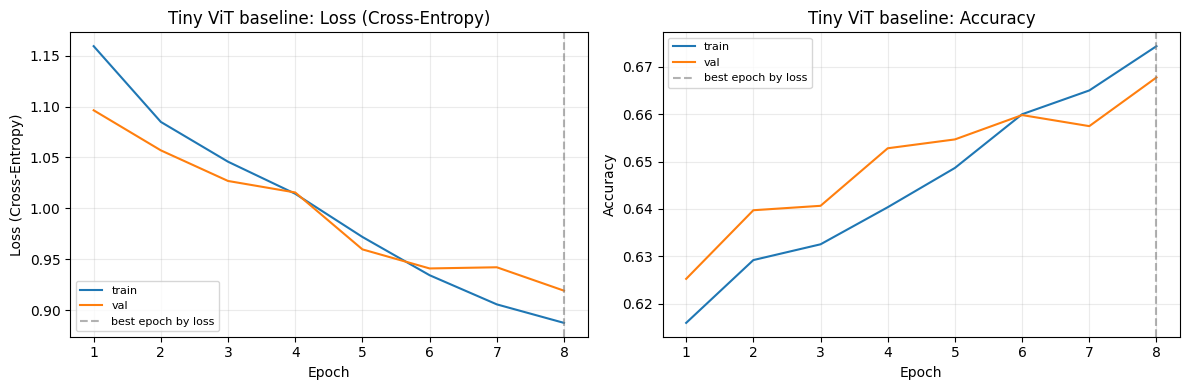

In [16]:
EPOCHS = 8
LR = 3e-4
WEIGHT_DECAY = 1e-2
checkpoint_path = "/kaggle/working/checkpoints/vit_baseline.pt"

seed_everything(SEED)

model = TinyViT(**vit_config).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
train_history = fit_model(
    model, EPOCHS, train_loader, val_loader,
    optimizer, checkpoint_path, device, scheduler
)
model = train_history["model"]
plot_history(train_history, f"Tiny ViT baseline")

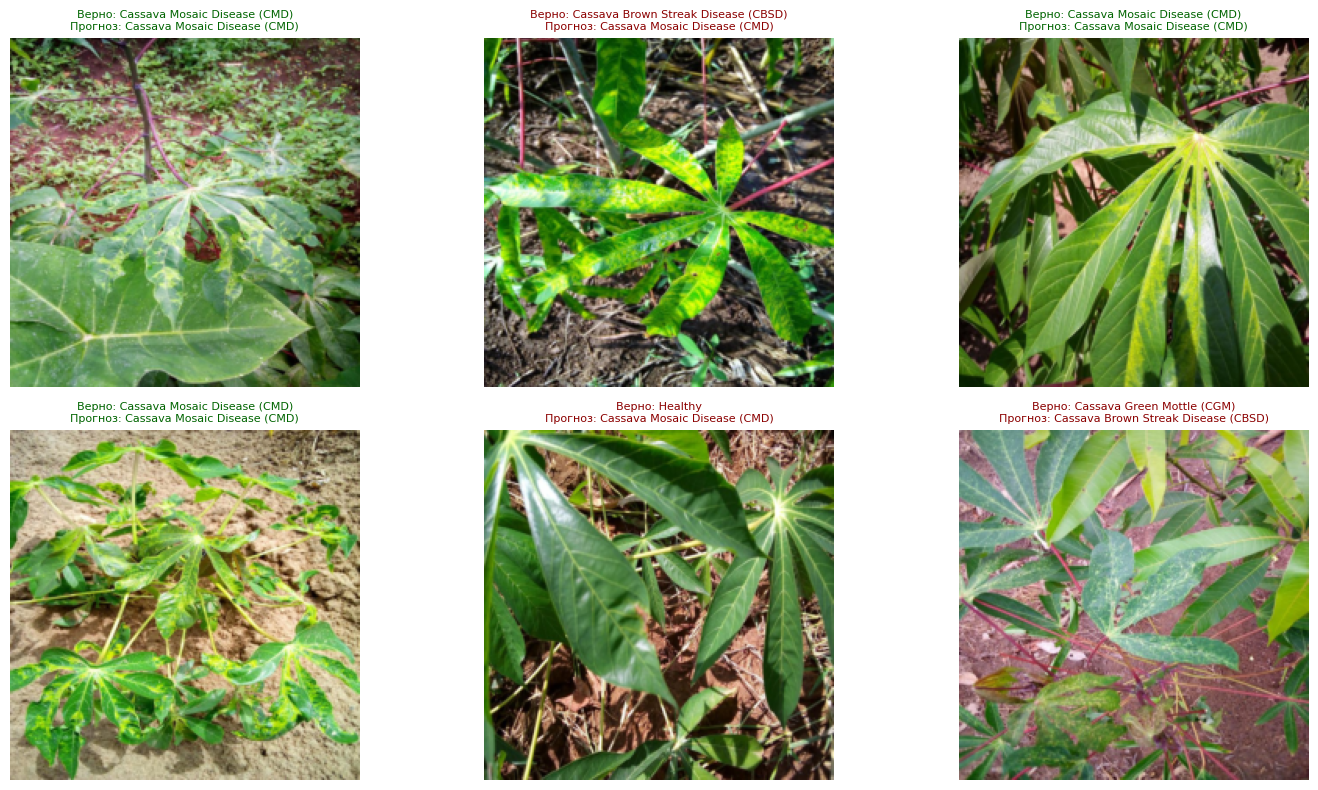

In [17]:
# Фиксируем валидационную подвыборку для двух следующих исследований.
batch = next(iter(val_loader))
x, y = batch
exp_x = x[:6].to(device)
exp_y = y[:6].to(device)
model.eval()
with torch.no_grad():
    exp_logits = model(exp_x)
    exp_predictions = exp_logits.argmax(dim=-1)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, ax in enumerate(axes.ravel()):
    true_id, pred_id = exp_y[i].item(), exp_predictions[i].item()
    ax.imshow(exp_x[i].detach().cpu().permute(1, 2, 0))
    ax.set_title(
        f"Верно: {label_names[str(true_id)]}\n"
        f"Прогноз: {label_names[str(pred_id)]}",
        fontsize=8,
        color="darkgreen" if true_id == pred_id else "darkred",
    )
    ax.axis("off")
plt.tight_layout(); plt.show()

Test loss: 0.9315 | Test accuracy: 65.47%


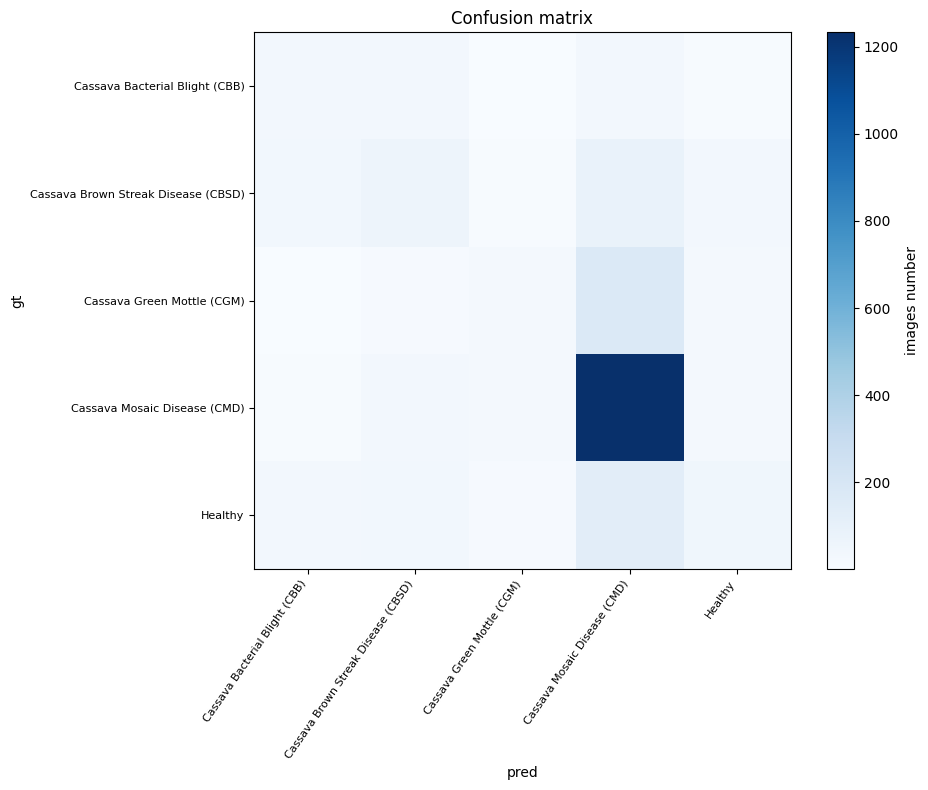

In [18]:
test_metrics = evaluate(model, test_loader, device)
print(
    f"Test loss: {test_metrics['val_loss']:.4f} | "
    f"Test accuracy: {test_metrics['val_accuracy']:.2%}"
)

num_classes = len(label_names)
confusion = torch.zeros(num_classes, num_classes, dtype=torch.long)
model.eval()
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        y = y.cpu()
        prediction = model(x).argmax(dim=-1).cpu()
        confusion += torch.bincount(y * num_classes + prediction,
                                    minlength=num_classes ** 2).reshape(num_classes, num_classes)

class_names = [
    label_names[str(i)]
    for i in range(num_classes)
]
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(confusion.numpy(), cmap="Blues")
ax.set_xticks(range(num_classes), labels=class_names, rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(num_classes), labels=class_names, fontsize=8)
ax.set(
    xlabel="pred",
    ylabel="gt",
    title="Confusion matrix",
)
plt.colorbar(im, ax=ax, label="images number")
plt.tight_layout()
plt.show()